*Chú giải trước cell gốc 0 (đánh số từ 0).*

**Cách đọc dự án phân loại cảm xúc IMDB**

Mục tiêu của bài là nhận một review tiếng Anh và dự đoán một trong hai nhãn: positive hoặc negative. Đây là học có giám sát: các review dùng huấn luyện đã có nhãn. Mô hình học mối liên hệ giữa nội dung và nhãn rồi dự đoán cho review mới.

Notebook sử dụng thuật toán qua scikit-learn và TensorFlow/Keras. Code tổ chức việc làm sạch dữ liệu, biểu diễn văn bản, huấn luyện, chọn siêu tham số và đánh giá; không tự cài đặt toàn bộ thuật toán từ đầu.

Luồng cần nắm:

~~~
Review + nhãn → bỏ trùng → làm sạch → lemmatization
    ├─ Chia train/test → Count hoặc TF-IDF → Naive Bayes hoặc Logistic
    └─ Mã hóa nhãn → chia train/test → token ID → padding → Embedding → BiLSTM
~~~

Mỗi nhánh là một cách giải cùng bài toán. Kết quả của mô hình này không được đưa làm đầu vào cho mô hình khác. Có ba họ mô hình, tạo ra năm cấu hình so sánh: hai cấu hình Naive Bayes, hai Logistic và một BiLSTM.

Bản học này giữ nguyên code và output của notebook bạn gửi, chỉ chèn phần giải thích. Những số đo mô hình bên dưới là output đã lưu, chưa được huấn luyện lại trong lần phân tích này. Một số output không khớp nhau; các chú thích sẽ chỉ rõ. Không xem các con số đã lưu là bảo đảm kết quả của mọi lần chạy.

Thứ tự học phù hợp là: hiểu một dòng dữ liệu → theo dõi một câu qua tiền xử lý → hiểu vector → hiểu mô hình dùng vector → hiểu cách kiểm tra dự đoán. Sau đó mới đọc phần BiLSTM.


In [ ]:
import os
import re
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

import nltk


from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

*Chú giải trước cell gốc 1 (đánh số từ 0).*

**Một dòng dữ liệu có ý nghĩa gì?**

File CSV gồm hai cột:

| Cột | Ý nghĩa | Vai trò |
|---|---|---|
| review | Nội dung đánh giá phim bằng tiếng Anh | Đầu vào X |
| sentiment | positive hoặc negative | Nhãn đúng y |

Kiểm tra trực tiếp file bạn gửi cho kết quả: 50.000 dòng, 25.000 positive và 25.000 negative; không có ô null hoặc review rỗng/chỉ có khoảng trắng. Không có lớp neutral. Mô hình này dự đoán cảm xúc của review, không được huấn luyện để dự đoán thể loại phim, doanh thu hoặc chất lượng khách quan của một bộ phim.

Đường dẫn /content/IMDB Dataset.csv là vị trí file trong phiên Colab. Nó không phải tên một phương pháp NLP.

data.info() giúp xem kiểu dữ liệu và giá trị thiếu; data.head() giúp nhìn vài dòng đầu. Đây là bước khám phá dữ liệu, chưa phải huấn luyện.


In [ ]:
data = pd.read_csv('/content/IMDB Dataset.csv')
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


# Tiền xử lý dữ liệu

*Chú giải trước cell gốc 3 (đánh số từ 0).*

**Vì sao bỏ review trùng trước khi chia train/test?**

data.duplicated().sum() đếm các dòng trùng hoàn toàn, không tính lần xuất hiện đầu. drop_duplicates(subset='review') giữ review đầu tiên và loại những lần có cùng nội dung.

Trong file thực tế, cả hai cách đếm đều cho 418 dòng dư; không phát hiện cùng một review có nhãn mâu thuẫn. Sau bỏ trùng:

| Nhãn | Số review |
|---|---:|
| positive | 24.884 |
| negative | 24.698 |
| Tổng | 49.582 |

Hai lớp vẫn gần cân bằng. Nếu một review xuất hiện trong train và một bản sao của nó xuất hiện trong test, điểm test có thể lạc quan vì mô hình đã gặp đúng nội dung đó. Bỏ trùng trước khi chia giảm vấn đề này.

drop_duplicates chỉ xử lý trùng chính xác. Hai review khác nhau ở vài dấu câu vẫn có thể được giữ; sau làm sạch, một số review cũng có thể trở thành giống nhau.

Báo cáo PDF có chỗ vẫn ghi 50.000 dòng sau bước bỏ trùng. Kích thước đúng của dữ liệu đã bỏ trùng trong notebook mới là 49.582.


In [ ]:
# Check if there are any duplicates
dup = data.duplicated().sum()
print(f'Có {dup} giá trị bị trùng lặp')

Có 418 giá trị bị trùng lặp


In [ ]:
# Drop the duplicates
data = data.drop_duplicates(subset = 'review')
data

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


sentiment
positive    24884
negative    24698
Name: count, dtype: int64


(array([0, 1]), [Text(0, 0, 'negative'), Text(1, 0, 'positive')])

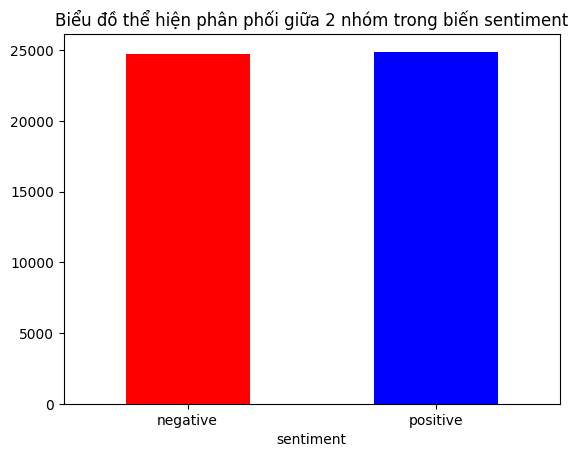

In [ ]:
# Data distribution
rating_counts = data['sentiment'].value_counts()
print(rating_counts)

data['sentiment'].value_counts().sort_index().plot.bar(color=['red', 'blue'])
plt.title('Biểu đồ thể hiện phân phối giữa 2 nhóm trong biến sentiment')
plt.xticks(rotation = 0)

In [ ]:
# The shape of data
data.shape

(49582, 2)

#Tiền xử lý

*Chú giải trước cell gốc 8 (đánh số từ 0).*

**Stopwords và vai trò của từ phủ định**

Stopwords là một danh sách từ được chọn để bỏ, thường gồm các từ phổ biến như the, is, this. Bỏ chúng giúp giảm số đặc trưng, nhưng tác động tới chất lượng phải được kiểm chứng trên bài toán cụ thể.

Trong phân loại cảm xúc, not có thể đổi nghĩa câu:

~~~
This movie is good.      → movie good
This movie is not good.  → movie not good
~~~

Vì vậy nhóm xóa các từ phủ định khỏi danh sách stop_words, nhằm giữ chúng trong review. Lưu ý hai thao tác ngược nhau: xóa một từ khỏi danh sách stopwords nghĩa là sẽ giữ từ ấy khi xử lý văn bản.

Output notebook mới ghi danh sách ban đầu có 198 từ, sau loại 19 mục phủ định còn 179. PDF ghi 179 → 160; đây là hai trạng thái tài nguyên khác nhau, không nên trộn số giữa hai bản. Code gọi nltk.download mà không đóng băng phiên bản corpus nên danh sách có thể thay đổi giữa các lần chạy.

Ý định giữ phủ định là hợp lý, nhưng thứ tự regex ở bước tiếp theo khiến nhiều dạng như don't hoặc wasn't vẫn mất phủ định. Đọc kỹ chú thích ngay trước clean_text.


In [ ]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
# Stopwords in English
stop_words = stopwords.words('english')
len(stop_words)

198

In [ ]:
# Remove the negative words in stopwords
negative_words=['no','not',"don't","aren't","couldn't",
                "didn't","doesn't","hadn't","hasn't","haven't",
                "isn't","mightn't","mustn't","needn't","shouldn't",
                "wasn't","weren't","won't","wouldn't"]
for negative_word in negative_words:
    if negative_word in stop_words:
        stop_words.remove(negative_word)

print("Stopwords sau khi loại bỏ những từ negative:",len(stop_words))

Stopwords sau khi loại bỏ những từ negative: 179


*Chú giải trước cell gốc 11 (đánh số từ 0).*

**Theo dõi clean_text từng bước**

| Lệnh | Biến đổi | Mục đích và đánh đổi |
|---|---|---|
| lower() | GOOD → good | Gộp cách viết hoa/thường; mất thông tin nhấn mạnh bằng chữ hoa |
| replace cặp thẻ br | Bỏ đúng chuỗi br đã chỉ định | Làm sạch HTML đơn giản, chưa xử lý mọi loại thẻ |
| REPLACE_BY_SPACE_RE.sub | Thay một số ký tự bằng khoảng trắng | Tách ký tự đặc biệt |
| re.sub("[^a-z]+", " ", sample) | Chỉ giữ chữ a–z và khoảng trắng | Đồng thời bỏ số, dấu câu, emoji và dấu nháy |
| split(" ") | Tạo danh sách token | Chưa có phân tích ngữ pháp |
| Lọc stop_words | Bỏ những token thuộc danh sách | Giảm từ phổ biến nhưng có thể mất thông tin |
| join | Nối token lại thành chuỗi | Đưa về dạng mà các bước sau nhận được |

Hai chi tiết có ảnh hưởng thực tế:

1. Với "I don't like this movie.", regex biến don't thành don và t. Hai mảnh này thuộc danh sách stopwords được dùng, nên câu có thể còn "like movie". Câu "I like this movie." cũng cho phần từ đó. Giữ nguyên mục don't trong negative_words không khắc phục được vì lúc lọc stopwords, token don't đã không còn.
2. Xóa cặp thẻ HTML bằng chuỗi rỗng có thể nối dính hai từ: good<br /><br />bad → goodbad. Thay thẻ bằng một khoảng trắng sẽ tránh trường hợp này.

Với "This movie is not good!", từ not còn nguyên và được giữ, nên các token có nghĩa còn lại là movie, not, good. Do đó phải phân biệt phủ định viết tách not với phủ định dạng viết tắt.

Regex đang phục vụ văn bản tiếng Anh. Nếu đưa trực tiếp tiếng Việt vào, quy tắc chỉ giữ a–z sẽ phá các chữ có dấu.

Phần giải thích này chỉ mô tả và chỉ ra hạn chế; code gốc bên dưới được giữ nguyên.


In [ ]:
REPLACE_BY_SPACE_RE = re.compile('[/(){}—[]|@,;‘?|।!-॥–’-]')

def clean_text(sample):
    if isinstance(sample, str):  # Check if sample is a string or not
        sample = sample.lower()
        sample = sample.replace("<br /><br />", "")
        sample = REPLACE_BY_SPACE_RE.sub(' ', sample)
        sample = re.sub("[^a-z]+", " ", sample)
        sample = sample.split(" ")
        sample = [word for word in sample if word not in stop_words]
        sample = " ".join(sample)
        return sample
    else:
        return ''

In [ ]:
# Process text, remove unwanted characters and unnecessary words
data['review'] = data['review'].apply(clean_text)
data.head()

,review,sentiment
0,one reviewers mentioned watching oz episode ho...,positive
1,wonderful little production filming technique ...,positive
2,thought wonderful way spend time hot summer we...,positive
3,basically family little boy jake thinks zombie...,negative
4,petter mattei love time money visually stunnin...,positive


*Chú giải trước cell gốc 13 (đánh số từ 0).*

**remove_emoji có còn thay đổi dữ liệu không?**

Hàm này loại ký tự nằm ngoài nhóm chữ/số/gạch dưới, khoảng trắng và dấu phẩy. Tên hàm là remove_emoji, nhưng biểu thức regex rộng hơn việc chỉ tìm emoji.

Trong thứ tự chạy hiện tại, clean_text trước đó đã chỉ giữ a–z và khoảng trắng. Vì vậy bước remove_emoji gần như dư thừa với dữ liệu đã qua clean_text. Không nên kết luận việc xóa emoji luôn có lợi: trong phân loại cảm xúc, emoji đôi khi là tín hiệu hữu ích.


In [ ]:
def remove_emoji(text):
    return re.sub(r'[^\w\s,]', '', str(text)) if isinstance(text, str) else text

# Apply remove_emoji function for 'review' column in DataFrame
data['review'] = data['review'].apply(remove_emoji)

*Chú giải trước cell gốc 14 (đánh số từ 0).*

**Tokenization và lemmatization là hai việc khác nhau**

WhitespaceTokenizer tách chuỗi theo khoảng trắng. Ví dụ "good movie" → ["good", "movie"]. Đây là tokenization.

WordNetLemmatizer tìm dạng từ trong từ điển WordNet, ví dụ movies → movie. Đây là lemmatization. Gộp các dạng từ có thể giảm số đặc trưng và giúp dùng chung bằng chứng giữa chúng.

Code gọi lemmatizer.lemmatize(w) mà không truyền loại từ. NLTK mặc định pos='n', tức danh từ. Vì thế không được giải thích rằng mọi động từ đều được đưa về gốc, chẳng hạn running chắc chắn thành run. Muốn xử lý động từ đúng vai trò cần xác định hoặc cung cấp POS tương ứng.

Lemmatization dựa vào từ điển; stemming thường cắt biến tố bằng quy tắc và có thể tạo chuỗi không phải từ hoàn chỉnh. Notebook này dùng lemmatization, không dùng stemming.

Đầu ra vẫn là một chuỗi văn bản đã chuẩn hóa. Việc biến văn bản thành số chỉ diễn ra trong vectorizer hoặc Keras Tokenizer phía sau.

Tham khảo: [NLTK WordNetLemmatizer](https://www.nltk.org/api/nltk.stem.wordnet.html).


In [ ]:
# Tokenize and lemmatize text
w_tokenizer = nltk.tokenize.WhitespaceTokenizer()
lemmatizer = nltk.stem.WordNetLemmatizer()
def lemmatize_text(text):
    st = ""
    for w in w_tokenizer.tokenize(text):
        st = st + lemmatizer.lemmatize(w) + " "
    return st
data['review'] = data.review.apply(lemmatize_text)
data

,review,sentiment
0,one reviewer mentioned watching oz episode hoo...,positive
1,wonderful little production filming technique ...,positive
2,thought wonderful way spend time hot summer we...,positive
3,basically family little boy jake think zombie ...,negative
4,petter mattei love time money visually stunnin...,positive
...,...,...
49995,thought movie right good job creative original...,positive
49996,bad plot bad dialogue bad acting idiotic direc...,negative
49997,catholic taught parochial elementary school nu...,negative
49998,going disagree previous comment side maltin on...,negative


#Naive Bayes

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

*Chú giải trước cell gốc 17 (đánh số từ 0).*

**Train, validation và test dùng để làm gì?**

x là review đã xử lý; y là nhãn sentiment. train_test_split đang tạo:

| Tập | Số dòng | Vai trò |
|---|---:|---|
| Train | 39.665 | Học mô hình và chọn siêu tham số bằng cross-validation |
| Test | 9.917 | Đánh giá sau khi đã chọn cấu hình |

test_size=0.2 dành khoảng 20% cho test. stratify=y duy trì gần đúng tỉ lệ hai lớp. random_state=0 làm phép chia có thể tái lập nếu dữ liệu đầu vào và thứ tự dòng giữ nguyên.

Trong bốn mô hình cổ điển, các tập này được dùng chung nên so sánh công bằng hơn. Không cần đổi nhãn chuỗi thành số để dùng các classifier sklearn này.

Những bước có học thống kê từ dữ liệu, như xây từ vựng và IDF, phải học từ train. Pipeline đặt vectorizer bên trong GridSearchCV đang thực hiện đúng nguyên tắc đó với từng fold.

Validation trong CV là các phần tạm tách từ train; không phải tập test bên ngoài. Dùng test nhiều lần để quyết định mọi thay đổi sẽ làm điểm test kém độc lập.


In [ ]:
from sklearn.model_selection import train_test_split
# Input
x = data['review'].values
# Output
y = data['sentiment'].values

# Train and test set
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 0, stratify = y)

print(f"Kích thước của dữ liệu huấn luyện: {X_train.shape[0]}.")
print(f"Kích thước của dữ liệu thử nghiệm: {X_test.shape[0]}.")

Kích thước của dữ liệu huấn luyện: 39665.
Kích thước của dữ liệu thử nghiệm: 9917.


#### Count Vectorizer

*Chú giải trước cell gốc 19 (đánh số từ 0).*

**CountVectorizer → Multinomial Naive Bayes → GridSearchCV**

CountVectorizer tạo từ vựng từ train và đếm số lần mỗi từ xuất hiện. Ví dụ minh họa với các cột [bad, good, movie]:

| Review | bad | good | movie |
|---|---:|---:|---:|
| good good movie | 0 | 2 | 1 |
| bad movie | 1 | 0 | 1 |

Mỗi hàng là một review, mỗi cột là một từ. Phần lớn ô bằng 0 nên ma trận được lưu thưa để tiết kiệm bộ nhớ. Cấu hình mặc định dùng unigram: đặc trưng là từng từ riêng lẻ, không lưu thứ tự từ. Vì thế "not good" và "good not" có cùng vector.

MultinomialNB học mức độ mỗi từ thường xuất hiện trong từng lớp. Với lớp c và vector x, mô hình so sánh:

$$s(c,x)=\log P(c)+\sum_j x_j\log P(t_j\mid c).$$

Chọn lớp có điểm lớn hơn. Đây là dạng log của định lý Bayes kết hợp giả định độc lập có điều kiện giữa đặc trưng khi biết lớp. "Naive" là giả định đơn giản hóa đó, không có nghĩa là từ ngữ thực tế độc lập.

Với đặc trưng đếm và V từ trong từ vựng:

$$P(t_j\mid c)=\frac{N_{cj}+\alpha}{\sum_k N_{ck}+\alpha V}.$$

alpha giúp làm trơn: một từ chưa xuất hiện trong lớp không làm xác suất cả review thành 0. alpha không phải learning rate.

Ví dụ tính tay, hoàn toàn giả lập: từ vựng [good,bad], prior hai lớp đều 0,5; positive đếm [3,1], negative đếm [1,3]. Với alpha=1, P(good|positive)=4/6 và P(good|negative)=2/6. Review "good good" cho hai điểm chưa chuẩn hóa 0,5×(4/6)² và 0,5×(2/6)². Chuẩn hóa thành positive=0,8, negative=0,2.

Pipeline ghép vectorizer với classifier. Khi fit, nó học từ vựng, biến đổi review rồi học NB; khi predict, nó dùng lại từ vựng đã học, không học lại trên review mới.

GridSearchCV thử alpha trong [0.1,0.5,1.0,1.5,2.0]. Với cv=5, mỗi lựa chọn được đánh giá bằng năm lần học/kiểm tra trên các phần của train. Cấu hình này dùng các fold phân tầng; không truyền scoring nên dùng accuracy của classifier. Tốt nhất nghĩa là tốt nhất trong lưới đã thử theo điểm CV, không phải tối ưu cho mọi giá trị alpha.

Tên multinomialnb__alpha trỏ tới tham số alpha của bước multinomialnb trong pipeline. Output hiện tại chọn alpha=2.0; PDF ghi 1.5.

Tham khảo: [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).


In [ ]:
# Make pipeline with CountVectorizer and MultinomialNB
pipeline = make_pipeline(CountVectorizer(), MultinomialNB())
# Experience with different alpha values
parameters = {'multinomialnb__alpha': [0.1, 0.5, 1.0, 1.5, 2.0]}
# Perform GridSearchCV
grid = GridSearchCV(pipeline, param_grid=parameters, cv=5)
grid.fit(X_train, y_train)

# Get the best alpha value
best_alpha_cv = grid.best_params_['multinomialnb__alpha']
print(f'Best alpha with Count Vectorizer: {best_alpha_cv}')

Best alpha with Count Vectorizer: 2.0


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import CountVectorizer

# Make pipeline with CountVectorizer and MultinomialNB with optimized alpha
nb_model_cv = make_pipeline(CountVectorizer(), MultinomialNB(alpha=best_alpha_cv))

# Train the model with training dataset
nb_model_cv.fit(X_train, y_train)

Pipeline(steps=[('countvectorizer', CountVectorizer()),
                ('multinomialnb', MultinomialNB(alpha=2.0))])

In [ ]:
nb_accuracy = nb_model_cv.score(X_test, y_test)
print(f'Độ chính xác của mô hình Naive Bayes với Count Vectorizer: {round(nb_accuracy*100)}%')

Độ chính xác của mô hình Naive Bayes với Count Vectorizer: 86%


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Predict on test set
nb_predictions = nb_model_cv.predict(X_test)

# Calculate and print the evaluation scores
accuracy = accuracy_score(y_test, nb_predictions)
print(f'Accuracy: {accuracy:.3f}')

# Print classification report
print('Classification Report:')
print(classification_report(y_test, nb_predictions))

Accuracy: 0.861
Classification Report:
              precision    recall  f1-score   support

    negative       0.85      0.88      0.86      4940
    positive       0.88      0.84      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



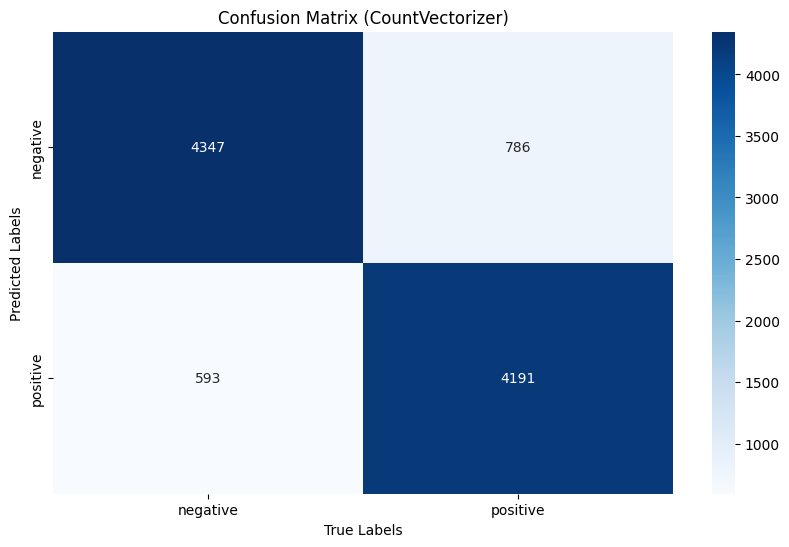

In [ ]:
# Confusion matrix
import seaborn as sns
matrix = confusion_matrix(nb_predictions,y_test)
matrix_df = pd.DataFrame(matrix, index=np.unique(y), columns=np.unique(y))
plt.figure(figsize=(10,6))
plt.tight_layout(pad=2.0)
sns.heatmap(matrix_df, annot=True, cmap="Blues", fmt="d")
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Confusion Matrix (CountVectorizer)")
plt.show()

#### TF-IDF Vectorizer

*Chú giải trước cell gốc 25 (đánh số từ 0).*

**TF-IDF thay đổi cách biểu diễn, mô hình NB vẫn là cùng một họ**

Count chỉ đếm. TF-IDF điều chỉnh trọng số theo mức độ phổ biến của từ trong nhiều review. Một từ xuất hiện trong rất nhiều review có IDF thấp hơn từ chỉ xuất hiện trong ít review.

Theo mặc định của sklearn:

$$idf(t)=\log\frac{1+n}{1+df(t)}+1,$$
$$v_t=count(t,d)\times idf(t),\qquad x=\frac{v}{\|v\|_2}.$$

n là số review train, df(t) là số review train có chứa t. tf mặc định ở đây là số lần đếm, rồi chuẩn hóa L2 cả vector; không nên thay bằng công thức tf chia độ dài mà vẫn gọi đó là đúng cấu hình mặc định của code này.

Ví dụ có ba review "good movie", "bad movie", "good good movie": movie có df=3 nên idf=1; good có df=2 nên idf≈1,2877; bad có df=1 nên idf≈1,6931. Với "good movie", vector trước chuẩn hóa trên [bad,good,movie] là [0,1,2877,1], sau chuẩn hóa xấp xỉ [0,0,7898,0,6134].

Độ hiếm không tự chứng minh một từ tích cực hoặc tiêu cực. Vectorizer học thống kê xuất hiện; classifier mới học mối liên hệ với nhãn. TF-IDF trong notebook cũng là unigram nên vẫn không biểu diễn thứ tự từ.

MultinomialNB có cơ sở tự nhiên với số đếm; sklearn cũng cho phép dùng trọng số TF-IDF không âm trong thực hành. Trong output hiện tại, alpha tốt nhất là 1.5 và accuracy test khoảng 86,78%.

Tham khảo: [sklearn về biểu diễn văn bản và công thức TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).


In [ ]:
# Make pipeline with TfidfVectorizer and MultinomialNB
pipeline = make_pipeline(TfidfVectorizer(), MultinomialNB())
# Experience with different alpha values
parameters = {'multinomialnb__alpha': [0.1, 0.5, 1.0, 1.5, 2.0]}
# Perform GridSearchCV
grid = GridSearchCV(pipeline, param_grid=parameters, cv=5)
grid.fit(X_train, y_train)

# Get the best alpha value
best_alpha_tf = grid.best_params_['multinomialnb__alpha']
print(f'Best alpha with TF-IDF Vectorizer: {best_alpha_tf}')

Best alpha with TF-IDF Vectorizer: 1.5


In [ ]:
# Make pipeline with TF-IDF and MultinomialNB with optimized alpha
nb_model_tf = make_pipeline(TfidfVectorizer(), MultinomialNB(alpha=best_alpha_tf))

# Train the model with training dataset
nb_model_tf.fit(X_train, y_train)

Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('multinomialnb', MultinomialNB(alpha=1.5))])

In [ ]:
nb_accuracy = nb_model_tf.score(X_test, y_test)
print(f'Độ chính xác của mô hình Naive Bayes với TF-IDF: {round(nb_accuracy*100)}%')

Độ chính xác của mô hình Naive Bayes với TF-IDF: 87%


In [ ]:
# Predict on test set
nb_pre = nb_model_tf.predict(X_test)
# Calculate and print the evaluation scores
accuracy_tf = accuracy_score(y_test, nb_pre)
print(f'Accuracy: {accuracy_tf:.3f}')

# Print classification report
print('Classification Report:')
print(classification_report(y_test, nb_pre))

Accuracy: 0.868
Classification Report:
              precision    recall  f1-score   support

    negative       0.86      0.88      0.87      4940
    positive       0.88      0.85      0.87      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



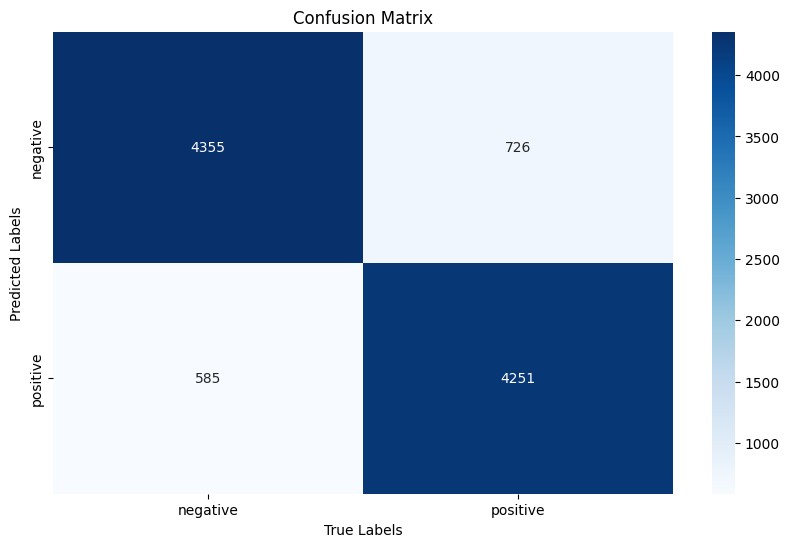

In [ ]:
# Confusion matrix
import seaborn as sns
matrix_tf = confusion_matrix(nb_pre,y_test)
matrix_tf = pd.DataFrame(matrix_tf, index=np.unique(y), columns=np.unique(y))
plt.figure(figsize=(10,6))
plt.tight_layout(pad=2.0)
sns.heatmap(matrix_tf, annot=True, cmap="Blues", fmt="d")
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Confusion Matrix")
plt.show()

#Maxent

In [ ]:
from sklearn.linear_model import LogisticRegression

#### Count Vectorizer

*Chú giải trước cell gốc 33 (đánh số từ 0).*

**Logistic Regression và tên MaxEnt**

Logistic Regression trong bài này là classifier nhị phân. Mô hình tính tổng bằng chứng:

$$z=w^\top x+b,\qquad P(positive\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$

x là Count hoặc TF-IDF; w và b được học từ dữ liệu có nhãn. Một hệ số dương đẩy điểm về phía positive, một hệ số âm đẩy về phía negative, với các đặc trưng khác giữ nguyên. Hệ số không phải định nghĩa cảm xúc bất biến của từ trong mọi ngữ cảnh.

Ví dụ giả lập: x=[count(good),count(bad)]=[2,1], w=[1,2;-1,5], b=-0,2. Khi đó z=2×1,2−1,5−0,2=0,7; sigmoid(z)≈0,668 nên chọn positive ở ngưỡng 0,5. Những trọng số này chỉ để minh họa, không lấy từ mô hình thật.

Khác cách ước lượng phân bố từ theo lớp của NB, Logistic học trực tiếp xác suất lớp từ đặc trưng, bằng tối ưu log loss cùng regularization.

MaxEnt là cách diễn giải mô hình qua nguyên lý entropy cực đại. Tiêu đề MaxEnt ở notebook đang nói đến Logistic Regression này, không phải một mô hình thứ tư tách biệt.

Tham số C là nghịch đảo cường độ regularization: C nhỏ → phạt trọng số mạnh hơn; C lớn → phạt yếu hơn. max_iter=1000 là trần vòng lặp bộ tối ưu, không phải số epoch BiLSTM.

GridSearch thử C trong [0.001,0.01,0.1,1,10,100] bằng 5-fold CV. Với Count, output chọn C=0.1.

Tham khảo: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [ ]:
# Make pipeline with CountVectorizer and Logistic Regression
pipeline = make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000))

# Experience with different values of C
parameters = {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]}

# Perform GridSearchCV
grid = GridSearchCV(pipeline, param_grid=parameters, cv=5)
grid.fit(X_train, y_train)

# Get the best C value
best_C_cv = grid.best_params_['logisticregression__C']
print(f'Best C with Count Vectorizer: {best_C_cv}')

Best C with Count Vectorizer: 0.1


In [ ]:
# Train model with best C value
lr_model_cv = make_pipeline(CountVectorizer(), LogisticRegression(C=best_C_cv, max_iter=1000))
lr_model_cv.fit(X_train, y_train)

Pipeline(steps=[('countvectorizer', CountVectorizer()),
                ('logisticregression',
                 LogisticRegression(C=0.1, max_iter=1000))])

In [ ]:
# Evaluate the model accuracy
lr_accuracy_cv = lr_model_cv.score(X_test, y_test)
print(f'Độ chính xác của mô hình: {lr_accuracy_cv*100}%')

Độ chính xác của mô hình: 89.03902389835636%


In [ ]:
# Predict on test set
predictions_cv = lr_model_cv.predict(X_test)

# Print classification report
print(classification_report(y_test, predictions_cv))

              precision    recall  f1-score   support

    negative       0.89      0.89      0.89      4940
    positive       0.89      0.89      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



In [ ]:
# Total predictions
total_predictions_cv = len(predictions_cv)
# Number of correct predictions
correct_predictions_cv = sum(predictions_cv == y_test)
# Number of incorrect predictions
incorrect_predictions_cv = total_predictions_cv - correct_predictions_cv
# Result
print(f'Tổng số dự đoán của mô hình: {total_predictions_cv}')
print(f'Số dự đoán đúng: {correct_predictions_cv}')
print(f'Số dự đoán sai: {incorrect_predictions_cv}')

Tổng số dự đoán của mô hình: 9917
Số dự đoán đúng: 8830
Số dự đoán sai: 1087


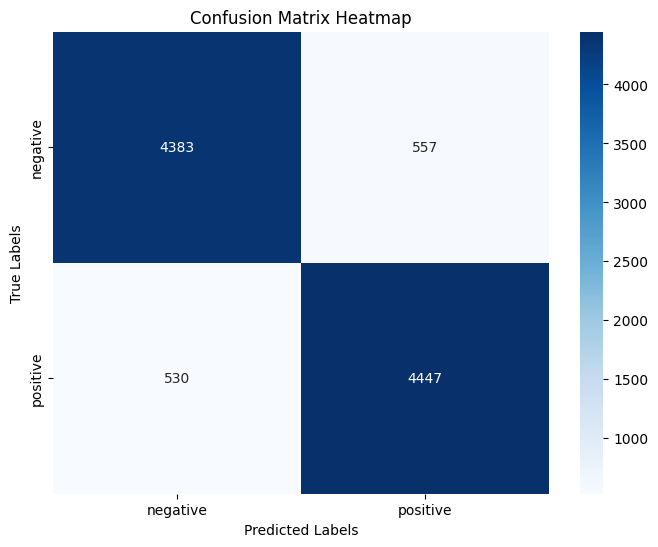

In [ ]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, predictions_cv)

# Create heatmap from confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=lr_model_cv.classes_, yticklabels=lr_model_cv.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Heatmap')
plt.show()

#### TF-IDF Vectorizer

*Chú giải trước cell gốc 40 (đánh số từ 0).*

**Vì sao TF-IDF + Logistic chọn C khác Count + Logistic?**

Đây vẫn là cùng loại classifier, nhưng x đã đổi từ số đếm sang trọng số TF-IDF có chuẩn hóa. Thang đo và phân bố đặc trưng đổi nên mức phạt phù hợp cũng có thể đổi. Không nên lấy C của một cách biểu diễn rồi mặc định là tốt cho cách còn lại.

Output hiện tại chọn C=10 cho TF-IDF. Accuracy test chính xác được lưu là 0.8950287385297974, tức khoảng 89,50%. classification_report chỉ hiển thị hai chữ số thập phân nên dòng accuracy hiện 0.90; nó không chứng minh accuracy chính xác bằng 90%.

TF-IDF không luôn thắng Count trên mọi dataset. Kết luận tại đây chỉ áp dụng cho cấu hình, phép chia và output đang có.


In [ ]:
# Make pipeline with CountVectorizer and Logistic Regression
pipeline = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))

# Experience with different values of C
parameters = {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]}
# Perform GridSearchCV
grid = GridSearchCV(pipeline, param_grid=parameters, cv=5)
grid.fit(X_train, y_train)

# Get the best C value
best_C_tf = grid.best_params_['logisticregression__C']
print(f'Best C with TF-IDF Vectorizer: {best_C_tf}')

Best C with TF-IDF Vectorizer: 10


In [ ]:
# Train model with best C value
lr_model_tf = make_pipeline(TfidfVectorizer(), LogisticRegression(C=best_C_tf, max_iter=1000))
lr_model_tf.fit(X_train, y_train)

Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('logisticregression',
                 LogisticRegression(C=10, max_iter=1000))])

In [ ]:
# Evaluate the model accuracy
lr_accuracy_tf = lr_model_tf.score(X_test, y_test)
print(f'Độ chính xác của mô hình: {lr_accuracy_tf*100}%')

Độ chính xác của mô hình: 89.50287385297973%


In [ ]:
# Predict on test set
predictions_tf = lr_model_tf.predict(X_test)

# Print classification report
print(classification_report(y_test, predictions_tf))

              precision    recall  f1-score   support

    negative       0.90      0.89      0.89      4940
    positive       0.89      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [ ]:
# Total predictions
total_predictions_tf = len(predictions_tf)
# Number of correct predictions
correct_predictions_tf = sum(predictions_tf == y_test)
# Number of incorrect predictions
incorrect_predictions_tf = total_predictions_tf - correct_predictions_tf
# Result
print(f'Tổng số dự đoán của mô hình: {total_predictions_tf}')
print(f'Số dự đoán đúng: {correct_predictions_tf}')
print(f'Số dự đoán sai: {incorrect_predictions_tf}')

Tổng số dự đoán của mô hình: 9917
Số dự đoán đúng: 8876
Số dự đoán sai: 1041


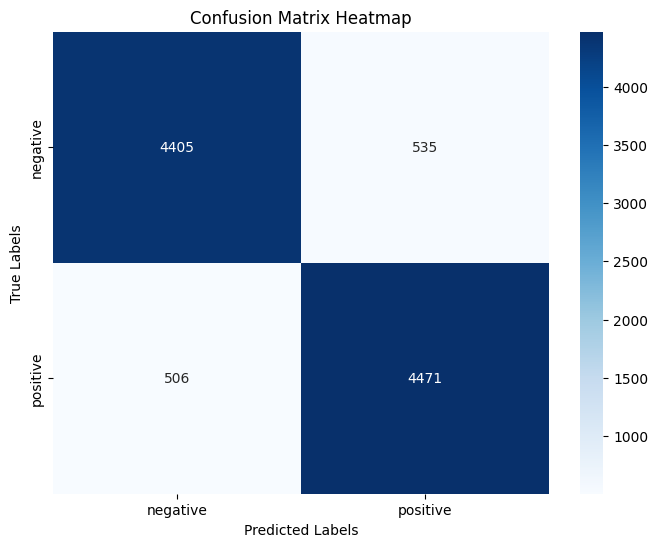

In [ ]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, predictions_tf)

# Create heatmap from confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=lr_model_tf.classes_, yticklabels=lr_model_tf.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Heatmap')
plt.show()

#Tfidf Vectorizer & Count Vectorizer

In [ ]:
from sklearn.pipeline import Pipeline

*Chú giải trước cell gốc 48 (đánh số từ 0).*

**Đọc bảng so sánh và hiểu các lần fit lặp lại**

Các pipeline ở đây dùng lại cùng cấu hình đã chọn trước đó, chỉ tự đặt tên bước như cv, tf, lr, mnb. Chúng không phải bốn thuật toán mới.

GridSearchCV mặc định đã refit cấu hình thắng trên toàn train. Code sau đó tạo pipeline và fit lại; ở đoạn tổng hợp này lại fit một lần nữa. Đây là phần lặp tính toán để tạo bảng so sánh.

| Cấu hình | Tham số tốt nhất | Accuracy train | Accuracy test |
|---|---|---:|---:|
| Count + NB | alpha=2.0 | 89,31% | 86,09% |
| TF-IDF + NB | alpha=1.5 | 90,13% | 86,78% |
| Count + Logistic | C=0.1 | 96,36% | 89,03% |
| TF-IDF + Logistic | C=10 | 98,07% | 89,50% |

Đây là số từ output đã lưu, chưa được chạy lại khi tạo chú giải. Bốn cấu hình dùng cùng test 9.917 review. TF-IDF + Logistic đúng 8.876 review; Count + Logistic đúng 8.829, chênh 47 review, tương đương khoảng 0,47 điểm phần trăm.

Train cao hơn test là khoảng cách khái quát hóa cần theo dõi. Không dùng train accuracy để chọn mô hình thắng. Cũng chưa thể suy ra mức overfitting chỉ từ một số đo duy nhất.

Tên “Multinomial Logistic Regression” trong bảng là nhãn tác giả đặt. Bài này vẫn chỉ có hai lớp; tên rõ hơn là Logistic Regression nhị phân.

Ở các hình confusion matrix: NB gọi hàm theo thứ tự predicted, true nên hàng là dự đoán và cột là thực tế; nhãn trục hiện đi cùng quy ước ấy. Logistic dùng true, predicted nên hàng là thực tế, cột là dự đoán. Hai loại hình bị chuyển vị so với nhau, cần đọc trục trước khi xác định FP/FN.


In [ ]:
cv_log = Pipeline([
('cv', CountVectorizer()),
('lr', LogisticRegression(C = best_C_cv, max_iter=1000))])
cv_log.fit(X_train, y_train)
cv_log.score(X_train, y_train), cv_log.score(X_test, y_test)

(0.9637463758981469, 0.8903902389835636)

In [ ]:
cv_mnb = Pipeline([
('cv', CountVectorizer()),
('mnb', MultinomialNB(alpha = best_alpha_cv))])
cv_mnb.fit(X_train, y_train)
cv_mnb.score(X_train, y_train), cv_mnb.score(X_test, y_test)

(0.8931047523005168, 0.860945850559645)

In [ ]:
tf_log = Pipeline([
('tf', TfidfVectorizer()),
('lr', LogisticRegression(C = best_C_tf, max_iter = 1000))])
tf_log.fit(X_train, y_train)
tf_log.score(X_train, y_train), tf_log.score(X_test, y_test)

(0.9807134753561074, 0.8950287385297974)

In [ ]:
tf_mnb = Pipeline([
('tf', TfidfVectorizer()),
('mnb', MultinomialNB(alpha = best_alpha_tf))])
tf_mnb.fit(X_train, y_train)
tf_mnb.score(X_train, y_train), tf_mnb.score(X_test, y_test)

(0.9012731627379301, 0.8678027629323384)

In [ ]:
def classifier_metrics(report_title, model):
  preds = model.predict(X_test)
  train_accuracy = model.score(X_train, y_train)
  test_accuracy = accuracy_score(y_test, preds)
  metrics = {
  'model': report_title,
  'train_accuracy': train_accuracy,
  'test_accuracy': test_accuracy,
  }
  df = pd.DataFrame(metrics.items()).T
  df.columns = df.iloc[0]
  df = df[1:]
  return df


In [ ]:
metrics1 = classifier_metrics('CountVectorizer + Multinomial Logistic Regression', cv_log)
metrics2 = classifier_metrics('TF-IDF + Multinomial Logistic Regression', tf_log)
metrics3 = classifier_metrics('CountVectorizer + Multinomial Naive Bayes', cv_mnb)
metrics4 = classifier_metrics('TF-IDF + Multinomial Naive Bayes', tf_mnb)
metrics = pd.concat([metrics1, metrics2, metrics3, metrics4]).sort_values('test_accuracy')
metrics

,model,train_accuracy,test_accuracy
1,CountVectorizer + Multinomial Naive Bayes,0.893105,0.860946
1,TF-IDF + Multinomial Naive Bayes,0.901273,0.867803
1,CountVectorizer + Multinomial Logistic Regression,0.963746,0.89039
1,TF-IDF + Multinomial Logistic Regression,0.980713,0.895029


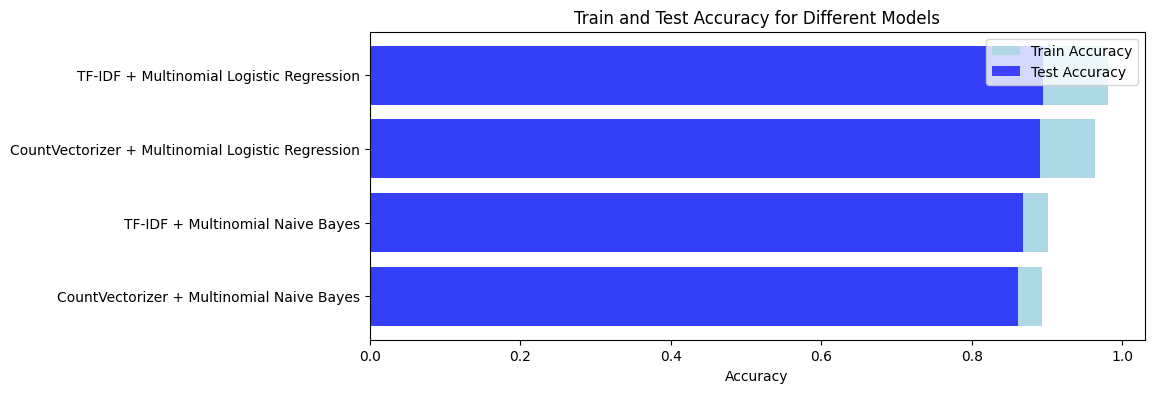

In [ ]:
# Create chart
fig, ax = plt.subplots(figsize=(10, 4))

# Train accuracy
ax.barh(metrics['model'], metrics['train_accuracy'], color='lightblue', label='Train Accuracy')

# Test accuracy
ax.barh(metrics['model'], metrics['test_accuracy'], color='blue', alpha=0.7, label='Test Accuracy')

# Set label and title
ax.set_xlabel('Accuracy')
ax.set_title('Train and Test Accuracy for Different Models')

# Show legend
ax.legend()

# Show the graph
plt.show()

#Mô hình học sâu

*Chú giải trước cell gốc 56 (đánh số từ 0).*

**Chuyển sang nhánh học sâu: đổi cả cách biểu diễn**

NB và Logistic nhận vector tổng hợp số lần/trọng số từ. BiLSTM nhận một chuỗi token ID có thứ tự rồi học embedding cho chúng. BiLSTM trong notebook không nhận ma trận Count hoặc TF-IDF.

Tokenizer ở đoạn này fit toàn dữ liệu chỉ để thống kê từ vựng; output Vocabulary Size=91.802 là len(word_index)+1, đã tính thêm vị trí dự trữ. Ở bước chuẩn bị đầu vào chính, tokenizer được tạo mới và fit trên train_sentences, nên phép đếm toàn dữ liệu này không được dùng làm từ vựng dự đoán cuối.

Output độ dài review trung bình khoảng 119,964 từ là sau tiền xử lý, không phải độ dài văn bản gốc. Trung bình không đảm bảo mọi review dưới 200 từ; muốn đánh giá tác động max_length cần xem thêm phân bố và tỉ lệ vượt ngưỡng.

Làm sạch quá mạnh có thể ảnh hưởng đến thông tin về cấu trúc câu mà BiLSTM sử dụng. Giữ stopwords hay dấu câu cho một nhánh học sâu là một lựa chọn cần thử bằng validation, không có quy tắc mọi nhánh phải xử lý giống nhau.


In [ ]:
reviews = data['review']
tokenizer = Tokenizer()
tokenizer.fit_on_texts(reviews)

# Get the total number of unique words in the vocabulary
vocab_size = len(tokenizer.word_index) + 1

# Print the vocabulary size and embedding dimension
print(f"Vocabulary Size: {vocab_size}")

Vocabulary Size: 91802


In [ ]:
s = 0.0
for i in data['review']:
    word_list = i.split()
    s = s + len(word_list)
print("Average length of each review : ",s/data.shape[0])

Average length of each review :  119.96399903190674


*Chú giải trước cell gốc 58 (đánh số từ 0).*

**Mã hóa nhãn cho sigmoid**

LabelEncoder đổi nhãn thành số theo thứ tự classes_. Với hai nhãn trong bài: negative→0, positive→1. Nhờ đó một đầu ra sigmoid có thể được so với nhãn 0/1 bằng binary cross-entropy.

Mã số của lớp chỉ là quy ước. Luôn kiểm tra encoder.classes_ trước khi giải nghĩa xác suất. Một token ID của từ cũng chỉ là mã tra cứu, không phải mức độ tích cực/tiêu cực hay một đại lượng có thể so sánh lớn nhỏ.


In [ ]:
reviews = data['review'].values
labels = data['sentiment'].values
encoder = LabelEncoder()
encoded_labels = encoder.fit_transform(labels)

*Chú giải trước cell gốc 59 (đánh số từ 0).*

**BiLSTM đang chia dữ liệu lại**

Phép chia này có stratify và test_size=0.2, nhưng không có random_state. Vì vậy BiLSTM dùng một phép chia khác bốn mô hình cổ điển; chạy lại cũng có thể cho test khác.

Sau đó model.fit(validation_split=0.1) lấy tiếp 10% phần train_sentences làm validation:

| Phần | Số review | Công dụng |
|---|---:|---|
| Train thực sự cập nhật trọng số | 35.698 | Học embedding và các lớp mạng |
| Validation | 3.967 | Theo dõi mô hình sau mỗi epoch |
| Test | 9.917 | Kiểm tra cuối |

Tỉ lệ tổng thể xấp xỉ 72% / 8% / 20%. Không phải 80% train + 10% validation + 20% test.

Keras lấy các mẫu cuối của mảng train làm validation trước khi shuffle lúc fit. Đây không phải cơ chế phân tầng validation tự động.

Tokenizer chính bên dưới được fit trên toàn train_sentences trước khi Keras giữ lại validation. Vì thế validation góp vào thống kê từ vựng, dù nhãn validation không dùng cập nhật trọng số. Thiết kế chặt hơn là chia validation riêng trước, rồi fit tokenizer chỉ trên train thực sự.

Tham khảo: [Keras model.fit và validation_split](https://keras.io/api/models/model_training_apis/).


In [ ]:
train_sentences, test_sentences, train_labels, test_labels = train_test_split(reviews, encoded_labels, test_size = 0.2, stratify = encoded_labels)

*Chú giải trước cell gốc 60 (đánh số từ 0).*

**Token ID, OOV, padding và truncation**

Tokenizer học bảng ánh xạ từ→ID từ train. Ví dụ giả lập: movie→2, good→3, not→4 thì "movie not good"→[2,4,3]. Khác Count/TF-IDF, vị trí token vẫn được giữ.

num_words=3000 giới hạn các ID được sử dụng khi chuyển thành chuỗi. word_index vẫn có thể chứa rất nhiều từ; không được lấy độ dài word_index để kết luận rằng giới hạn 3000 không hoạt động.

oov_token='' là tên chuỗi rỗng của một token đặc biệt, khác với None. Trong triển khai Keras legacy, nó vẫn được cấp ID riêng, thường là 1. Từ ngoài giới hạn được đưa về ID OOV. Nó không biến thành chuỗi rỗng trong tensor và không phải số 0.

ID 0 dùng cho padding. Với maxlen=5, chuỗi [2,4,3] được đệm post thành [2,4,3,0,0]. Embedding_dim=200 ở bước sau là số chiều của mỗi vector từ; max_length=200 ở đây là số vị trí từ. Hai số cùng bằng 200 nhưng nói về hai trục khác nhau.

Có một khác biệt giữa ý định và code:

~~~
trunc_type='post'
pad_sequences(..., padding='post', maxlen=max_length)
~~~

Biến trunc_type không được truyền vào. pad_sequences mặc định truncating='pre', nên review dài được cắt ở đầu, giữ 200 token cuối. padding='post' chỉ quyết định chỗ thêm số 0, không quyết định chỗ cắt token.

Ví dụ chuỗi [1,2,3,4,5], maxlen=3:

| Cấu hình | Kết quả |
|---|---|
| truncating='pre' như code thực tế | [3,4,5] |
| truncating='post' như biến khai báo | [1,2,3] |

Muốn làm đúng theo biến khai báo phải truyền truncating=trunc_type. Đây là gợi ý học/cải thiện; code gốc bên dưới chưa được thay đổi.

Tham khảo: [pad_sequences](https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences), [mã nguồn Keras legacy Tokenizer](https://github.com/keras-team/keras/blob/v3.3.3/keras/src/legacy/preprocessing/text.py).


In [ ]:
# Hyperparameters of the model
vocab_size = 3000
oov_tok = ''
embedding_dim = 200
max_length = 200
padding_type='post'
trunc_type='post'

# Tokenize sentences
tokenizer = Tokenizer(num_words = vocab_size, oov_token=oov_tok)
tokenizer.fit_on_texts(train_sentences)
word_index = tokenizer.word_index

# Convert train dataset to sequence and pad sequences
train_sequences = tokenizer.texts_to_sequences(train_sentences)
train_padded = pad_sequences(train_sequences, padding='post', maxlen=max_length)

# Convert test dataset to sequence and pad sequences
test_sequences = tokenizer.texts_to_sequences(test_sentences)
test_padded = pad_sequences(test_sequences, padding='post', maxlen=max_length)

*Chú giải trước cell gốc 61 (đánh số từ 0).*

**Đọc kiến trúc BiLSTM từ đầu vào đến xác suất**

Với B review trong một batch:

| Thành phần | Hình dạng đầu ra | Vai trò |
|---|---|---|
| Chuỗi ID đã pad | (B,200) | 200 vị trí mỗi review |
| Embedding(3000,200) | (B,200,200) | Tra mỗi ID thành vector 200 chiều |
| Bidirectional(LSTM(64)) | (B,128) | Hai hướng, mỗi hướng tóm tắt bằng 64 giá trị |
| Dropout(0.2) | (B,128) | Ngẫu nhiên bỏ 20% thành phần khi training |
| Dense(24, relu) | (B,24) | Kết hợp đặc trưng và đưa phi tuyến |
| Dense(1, sigmoid) | (B,1) | Ước lượng xác suất lớp positive |

Embedding được khởi tạo và học cùng mạng từ dữ liệu của bài. Code không nạp Word2Vec, GloVe hay embedding pretrained.

LSTM đọc các vị trí của chuỗi và duy trì hai trạng thái: cell state c_t và hidden state h_t. Cổng quên quyết định giữ bao nhiêu bộ nhớ cũ; cổng vào quyết định ghi bao nhiêu thông tin mới; cổng ra quyết định thông tin nào được xuất qua hidden state. Có thể đọc phần ghi nhớ cốt lõi dưới dạng:

$$c_t=f_t\odot c_{t-1}+i_t\odot \tilde c_t,\qquad h_t=o_t\odot\tanh(c_t).$$

Các cổng là vector được mạng học, không phải danh sách từ được người viết code chỉ định. Cell state và hidden state là hai khái niệm khác nhau.

BiLSTM dùng một LSTM đọc theo thứ tự tiến và một LSTM đọc ngược trên cùng review. Nó ghép hai vector đầu ra, nên 64+64=128. 64 không phải số lớp hay số từ tối đa. Với cấu hình này không bật return_sequences, nên lớp trả một biểu diễn tổng hợp cho mỗi review.

Input có dạng chuỗi vì LSTM xử lý chuỗi. Sequential chỉ là cách ghép các lớp theo thứ tự, không phải nguyên nhân phải token hóa thành sequence.

Code chưa đặt mask_zero=True trong Embedding, nên các vị trí padding chưa được tự động đánh dấu để LSTM bỏ qua. Vector của ID 0 cũng không tự được đảm bảo luôn là vector toàn 0.

Khi đã build, số tham số học được suy từ kiến trúc là 738.801: Embedding 600.000, BiLSTM 135.680, Dense 3.096 và Dense cuối 25. Số này chưa tính trạng thái optimizer. Output summary đang ghi unbuilt/0 là trạng thái trước khi mạng được build, không có nghĩa mô hình sau huấn luyện không có tham số.

Tham khảo: [Embedding và mask_zero](https://keras.io/api/layers/core_layers/embedding/), [Bidirectional](https://keras.io/2/api/layers/recurrent_layers/bidirectional/).


In [ ]:
# Model initialization
model = keras.Sequential([
    keras.layers.Embedding(vocab_size, embedding_dim, input_length=max_length),
    keras.layers.Bidirectional(keras.layers.LSTM(64)),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(24, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])
# Compile model
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
# Model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

*Chú giải trước cell gốc 62 (đánh số từ 0).*

**Mạng học như thế nào?**

Binary cross-entropy đo độ phù hợp giữa nhãn y∈{0,1} và xác suất p:

$$L=-\left[y\log p+(1-y)\log(1-p)\right].$$

Ví dụ y=1: p=0,9 cho loss≈0,105; p=0,1 cho loss≈2,303. Dự đoán sai một cách rất tự tin bị phạt mạnh. Loss khác accuracy: hai mô hình có thể đúng cùng số review nhưng khác mức tự tin, nên khác loss.

Trong mỗi batch, mạng tính dự đoán, tính loss, truyền ngược gradient rồi dùng Adam điều chỉnh trọng số. Embedding cũng được cập nhật trong quá trình này.

num_epochs=5 nghĩa là năm lượt đi qua phần dữ liệu dùng cập nhật trọng số. Keras mặc định batch_size=32 với mảng đầu vào như ở đây; log 1.116 bước mỗi epoch phù hợp với 35.698 review train. Validation được đánh giá sau epoch và không dùng để cập nhật trọng số qua backpropagation.

Dropout giúp hạn chế phụ thuộc vào một số thành phần, nhưng không bảo đảm hết overfitting. Khi dự đoán, lớp dropout không tiếp tục ngẫu nhiên xóa 20% như lúc training.

Notebook không dùng early stopping hoặc checkpoint để tự phục hồi epoch tốt nhất. model sau fit là mô hình ở epoch cuối.


In [ ]:
num_epochs = 5
history = model.fit(train_padded, train_labels,
                    epochs=num_epochs, verbose=1,
                    validation_split=0.1)

Epoch 1/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.8158 - loss: 0.4133 - val_accuracy: 0.8813 - val_loss: 0.3024
Epoch 2/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.8862 - loss: 0.2912 - val_accuracy: 0.8732 - val_loss: 0.3014
Epoch 3/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.8991 - loss: 0.2563 - val_accuracy: 0.8838 - val_loss: 0.3025
Epoch 4/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.9156 - loss: 0.2168 - val_accuracy: 0.8767 - val_loss: 0.3364
Epoch 5/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.9319 - loss: 0.1813 - val_accuracy: 0.8740 - val_loss: 0.3388


*Chú giải trước cell gốc 63 (đánh số từ 0).*

**Đọc loss và accuracy qua các epoch**

Output history hiện tại có:

| Epoch | Train accuracy | Validation accuracy | Validation loss |
|---|---:|---:|---:|
| 1 | 81,98% | 84,77% | 0,3935 |
| 2 | 88,32% | 88,76% | 0,2928 |
| 3 | 89,84% | 87,40% | 0,3028 |
| 4 | 91,60% | 88,71% | 0,2939 |
| 5 | 93,17% | 88,23% | 0,3339 |

Validation loss tốt nhất trong năm epoch ở epoch 2. Đến epoch 5, train loss tiếp tục giảm nhưng validation loss tăng, trong khi validation accuracy không cải thiện. Đây là dấu hiệu bắt đầu overfitting cần theo dõi.

Không nên chỉ nhìn train accuracy tăng rồi kết luận mô hình càng tốt. Cũng không nên lặp nguyên kết luận PDF rằng mô hình không overfit: output notebook mới có bằng chứng cần thận trọng hơn.

Nếu cải thiện thí nghiệm, có thể dùng EarlyStopping theo val_loss với restore_best_weights=True. Việc chọn dừng dựa vào validation; không dựa vào test.


In [ ]:
history_df = pd.DataFrame(history.history)

# Add an 'epoch' column to the DataFrame
history_df.insert(0, 'epoch', history_df.index + 1)

# Display the DataFrame
history_df

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.815816,0.413303,0.881270,0.302425
1,2,0.886156,0.291206,0.873204,0.301367
2,3,0.899126,0.256256,0.883791,0.302505
3,4,0.915597,0.216756,0.876733,0.336428
4,5,0.931873,0.181328,0.873960,0.338801


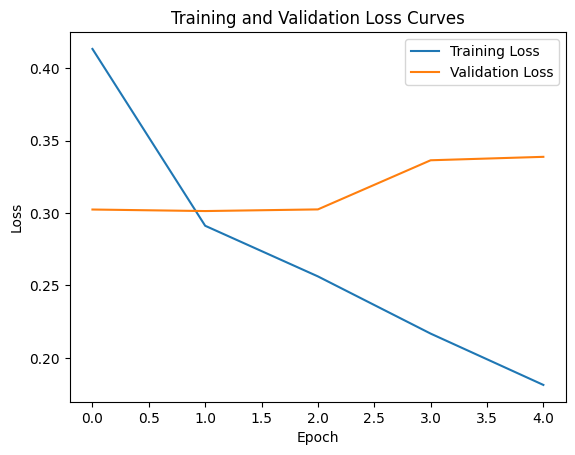

In [ ]:
# Plot training and validation loss curves
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# Add labels and title
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')

# Add a legend
plt.legend()

# Show the plot
plt.show()

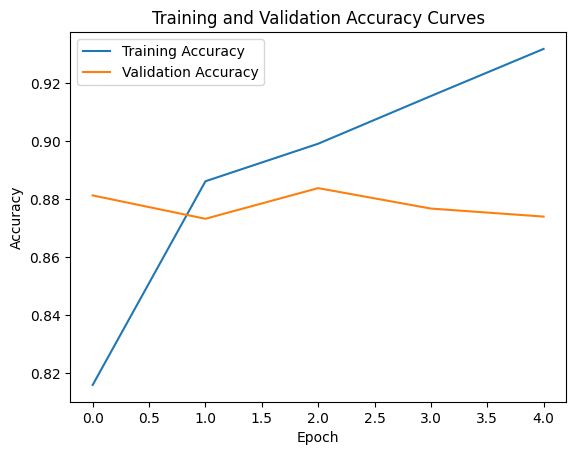

In [ ]:
# Plot training and validation accuracy curves
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Add labels and title
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy Curves')

# Add a legend
plt.legend()

# Show the plot
plt.show()

*Chú giải trước cell gốc 66 (đánh số từ 0).*

**Từ xác suất đến nhãn, rồi đánh giá**

model.predict trả các xác suất p. Vòng lặp quy đổi p≥0,5 thành nhãn 1, còn lại thành 0. Với LabelEncoder trong bài, 1 là positive.

Chọn positive làm lớp quan tâm:

| Đại lượng | Cách hiểu |
|---|---|
| TP | Positive thực tế, dự đoán positive |
| FP | Negative thực tế, dự đoán positive |
| FN | Positive thực tế, dự đoán negative |
| TN | Negative thực tế, dự đoán negative |

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN},$$
$$Precision=\frac{TP}{TP+FP},\qquad Recall=\frac{TP}{TP+FN},$$
$$F1=\frac{2\,Precision\,Recall}{Precision+Recall}.$$

Precision hỏi: trong các review mô hình gọi là positive, bao nhiêu thực sự positive? Recall hỏi: trong các review thực sự positive, mô hình tìm ra được bao nhiêu? support là số review thực tế của lớp, không phải số mô hình dự đoán.

classification_report báo từng lớp; macro avg lấy trung bình ngang nhau giữa các lớp, weighted avg cân theo support.

Cần lưu ý output không nhất quán: cell dự đoán đang ghi accuracy 0.8713320560653424, tức 87,13%, nhưng report ngay sau ghi accuracy 0.88. Với hai chữ số thập phân, 0.871332 phải làm tròn thành 0.87. Vì vậy hai output này không thể được coi là một cặp kết quả đồng nhất của cùng dự đoán đã lưu. Chưa xác định nguyên nhân từ file; có thể kiểm chứng bằng chạy lại hai cell liên tiếp trong cùng phiên, dùng cùng test_labels và pred_labels.

PDF ghi BiLSTM khoảng 87,51%, cũng không phải con số đang lưu tại cell dự đoán mới. Không ghép chúng thành một kết quả chung.

Ngoài ra, test của BiLSTM được chia lại độc lập. Có thể nói output cổ điển cao nhất đang là TF-IDF + Logistic; chưa thể dùng bảng hiện tại để chứng minh mô hình đó luôn thắng BiLSTM trong một so sánh kiểm soát đầy đủ.


In [ ]:
prediction = model.predict(test_padded)
# Get labels based on probability 1 if p>= 0.5 else 0
pred_labels = []
for i in prediction:
    if i >= 0.5:
        pred_labels.append(1)
    else:
        pred_labels.append(0)
print("Accuracy of prediction on test set : ", accuracy_score(test_labels,pred_labels))

310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Accuracy of prediction on test set :  0.8603408288797015


In [ ]:
print(classification_report(test_labels,pred_labels))

              precision    recall  f1-score   support

           0       0.87      0.84      0.86      4940
           1       0.85      0.88      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



**Bốn thao tác nhỏ để tự kiểm tra mình đã hiểu**

Các đoạn dưới chỉ là ví dụ để bạn chủ động chạy trong Colab sau các bước tương ứng. Chúng không được thêm thành code cell chạy tự động.

1. Theo dõi xem tiền xử lý có giữ ý nghĩa phủ định không:

~~~python
for sentence in [
    "This movie is good.",
    "This movie is not good.",
    "I like this movie.",
    "I don't like this movie.",
]:
    print(sentence, "->", lemmatize_text(remove_emoji(clean_text(sentence))))
~~~

Nếu hai câu khác nghĩa cùng thành một chuỗi, các mô hình phía sau không thể khôi phục phần thông tin đã mất đó chỉ từ đầu vào này.

2. Xem một vector thật của pipeline đã học:

~~~python
vec = lr_model_tf.named_steps["tfidfvectorizer"]
sentence = lemmatize_text(remove_emoji(clean_text("This movie is not good.")))
row = vec.transform([sentence])
words = vec.get_feature_names_out()
print([(words[j], round(float(row[0, j]), 4)) for j in row.indices])
~~~

Ở đây dùng transform vì từ vựng/IDF đã học. Không fit lại vectorizer trên một câu mới.

3. Xem Logistic đã học những hệ số nào:

~~~python
clf = lr_model_tf.named_steps["logisticregression"]
print("Thứ tự lớp:", clf.classes_)
weights = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())
print("Hệ số cao:", weights.nlargest(10))
print("Hệ số thấp:", weights.nsmallest(10))
~~~

Trong mô hình hai lớp, dấu hệ số hướng về lớp thứ hai trong classes_. Đây là mối liên hệ học được theo dữ liệu, không phải chứng minh quan hệ nhân quả.

4. Kiểm tra đúng padding, truncation và ID:

~~~python
print(encoder.classes_)
print(tokenizer.word_index.get(""))
print(train_sequences[0][:20])
print(train_padded.shape)
print(pad_sequences([[1, 2, 3, 4, 5]], maxlen=3, padding="post"))
~~~

Dòng cuối cho [3,4,5], minh họa truncating mặc định là pre.

Bạn đã nắm luồng bài khi tự giải thích được: vì sao không đưa thẳng chuỗi vào NB; Count khác TF-IDF ở đâu; alpha khác C ở đâu; LSTM nhận thứ tự từ qua bước nào; vì sao train accuracy cao chưa đủ; và tại sao phải dùng cùng tập test để so mô hình.

Nguồn đối chiếu là notebook NLP (1) (1).ipynb bạn gửi, IMDB Dataset.csv và báo cáo Đồ-án-NLP.pdf. Số liệu dataset đã được kiểm tra trực tiếp; kết quả mô hình trong chú giải được đọc từ output lưu sẵn. Code gốc và các output được bảo toàn để bạn so sánh, kể cả các điểm cần kiểm tra lại.